# 10_explainability
실제 학습/평가 결과를 읽는 실행 가능한 분석 노트북. 원자료 학습 재실행은 run_phase2.ps1 참조.


In [1]:
from pathlib import Path
import json, pandas as pd
from IPython.display import display, Markdown, Image
ROOT=Path.cwd()
if not (ROOT/'reports').exists(): ROOT=ROOT.parent
display(Markdown((ROOT/'reports/markdown/10_explainability_and_unknown_faults.md').read_text(encoding='utf-8')))
display(pd.read_csv(ROOT/'reports/tables/phase2/shap_sensor_rankings.csv').head(70))


# 설명과 미지 고장 탐지

## 주 모델과 TreeSHAP

주 모델은 GradientSHAP으로, 별도 XGBoost 비교 모델은 TreeSHAP으로 설명했다. 각 고장별 Test 실행1~5, sample240/480/960의15개 관측 창을 사용했다. 시계열 설명 배경64개는 Train에서만 뽑았다. GradientSHAP은 nsamples64이므로 근사 설명이며 전체 Test 대표성을 보장하지 않는다. 알려진 실제 Fault의 class logit을 설명한 것으로, 잘못 분류된 창에서도 그 클래스에 대한 기여가 계산된다.

원 변수별 순위는 파생 통계나 시차의 절대 기여를 합산해 계산했다. 절대값 합은 시차/특징 상쇄를 제거하므로 원 logit의 가산 분해 합과 같지 않다. 모델 기여도, 관측 센서 반응, 실제 원인 변수는 서로 다른 개념이다.

| fault | rank | variable | mean_absolute_attribution |
| --- | --- | --- | --- |
| 1 | 1 | xmeas_1 | 22.3192 |
| 1 | 2 | xmv_3 | 17.4963 |
| 1 | 3 | xmeas_18 | 9.4994 |
| 2 | 1 | xmeas_10 | 22.5974 |
| 2 | 2 | xmeas_34 | 14.6006 |
| 2 | 3 | xmeas_28 | 13.6047 |
| 3 | 1 | xmeas_21 | 9.0709 |
| 3 | 2 | xmeas_18 | 6.7119 |
| 3 | 3 | xmv_9 | 5.3125 |
| 4 | 1 | xmv_10 | 14.2036 |
| 4 | 2 | xmeas_21 | 6.6925 |
| 4 | 3 | xmv_11 | 6.4110 |
| 5 | 1 | xmv_11 | 14.8231 |
| 5 | 2 | xmeas_17 | 6.0586 |
| 5 | 3 | xmeas_21 | 5.6084 |
| 6 | 1 | xmv_11 | 24.0448 |
| 6 | 2 | xmv_3 | 14.7826 |
| 6 | 3 | xmeas_1 | 12.0421 |
| 7 | 1 | xmv_4 | 22.3165 |
| 7 | 2 | xmeas_18 | 8.1716 |
| 7 | 3 | xmeas_21 | 5.3405 |
| 8 | 1 | xmv_9 | 7.3646 |
| 8 | 2 | xmeas_18 | 6.6413 |
| 8 | 3 | xmeas_1 | 4.1219 |
| 9 | 1 | xmeas_21 | 6.6579 |
| 9 | 2 | xmeas_22 | 4.2391 |
| 9 | 3 | xmeas_18 | 3.8306 |
| 10 | 1 | xmeas_21 | 14.7458 |
| 10 | 2 | xmeas_18 | 9.9886 |
| 10 | 3 | xmv_9 | 5.1796 |
| 11 | 1 | xmeas_9 | 14.2509 |
| 11 | 2 | xmv_11 | 3.2177 |
| 11 | 3 | xmeas_17 | 2.9145 |
| 12 | 1 | xmv_11 | 18.1879 |
| 12 | 2 | xmeas_19 | 9.1330 |
| 12 | 3 | xmeas_18 | 8.0506 |
| 13 | 1 | xmv_9 | 21.7391 |
| 13 | 2 | xmeas_18 | 12.6560 |
| 13 | 3 | xmeas_21 | 4.9422 |
| 14 | 1 | xmeas_21 | 36.5127 |
| 14 | 2 | xmeas_9 | 17.1711 |
| 14 | 3 | xmeas_18 | 3.7090 |
| 15 | 1 | xmeas_21 | 18.0362 |
| 15 | 2 | xmeas_18 | 4.0118 |
| 15 | 3 | xmeas_9 | 3.7371 |
| 16 | 1 | xmeas_21 | 22.9770 |
| 16 | 2 | xmeas_18 | 12.3511 |
| 16 | 3 | xmv_9 | 8.5358 |
| 17 | 1 | xmeas_21 | 115.3409 |
| 17 | 2 | xmeas_9 | 13.9977 |
| 17 | 3 | xmv_1 | 1.7989 |
| 18 | 1 | xmeas_22 | 21.5918 |
| 18 | 2 | xmeas_13 | 10.5776 |
| 18 | 3 | xmv_11 | 8.4687 |
| 19 | 1 | xmeas_5 | 12.8977 |
| 19 | 2 | xmv_11 | 8.6719 |
| 19 | 3 | xmeas_17 | 7.2723 |
| 20 | 1 | xmeas_21 | 14.7337 |
| 20 | 2 | xmv_5 | 8.3922 |
| 20 | 3 | xmeas_13 | 4.9350 |

![주 모델 SHAP](../figures/phase2/primary_shap.png)

## 실제 B 센서 변화와 물리 해석 범위

정상 Train 실행400개 전체에서 센서별 기준 표준편차를 계산했다. 각 Fault의500개 Test 실행에서 주입 전 sample121~160 평균과 주입 후 sample161~960 평균 차이를 이 기준으로 표준화했다. B 반응 표는 b_fault_sensor_response.csv에 있다. 모델이 참조한 센서가 실제 변화했는지 이 표와20개 시계열 그림을 대조할 수 있다.

A 공개 카탈로그의 Fault1~15는 원료·냉각·동역학·밸브 시나리오 해석의 참고다. 다만 B의 시뮬레이터 구현·운전모드·원인 변수의 측정 열 대응이 충분히 공개되지 않아 공통 ID만으로 원인 적중률을 계산하지 않았다. 예를 들어 냉각수 출구 온도는 냉각수 입구 온도 원인과 다르며, 제어입력은 고장 원인일 수도 보상 반응일 수도 있다. Fault16~20의 공개 원인은 UNKNOWN으로 유지했다. Source가 충돌하는 A Fault21은 B에 없고 학습 대상도 아니다.

| fault | public_scenario_reference | observed_top3 | shap_top3 |
| --- | --- | --- | --- |
| 1 | A/C 원료 비율(B 일정) | xmeas_1, xmv_3, xmeas_4 | xmeas_1, xmv_3, xmeas_18 |
| 2 | B 조성(A/C 일정) | xmeas_34, xmeas_10, xmv_6 | xmeas_10, xmeas_34, xmeas_28 |
| 3 | D 원료 온도 | xmeas_21, xmv_10, xmeas_20 | xmeas_21, xmeas_18, xmv_9 |
| 4 | Reactor 냉각수 입구 온도 | xmv_10, xmeas_20, xmv_9 | xmv_10, xmeas_21, xmv_11 |
| 5 | Condenser/Separator 냉각수 입구 온도 | xmv_11, xmeas_11, xmeas_19 | xmv_11, xmeas_17, xmeas_21 |
| 6 | A 원료 공급 손실 | xmeas_16, xmeas_7, xmeas_31 | xmv_11, xmv_3, xmeas_1 |
| 7 | C header 압력 손실 | xmv_4, xmv_9, xmeas_19 | xmv_4, xmeas_18, xmeas_21 |
| 8 | A/B/C 원료 조성 | xmeas_29, xmeas_31, xmeas_25 | xmv_9, xmeas_18, xmeas_1 |
| 9 | D 원료 온도 | xmv_9, xmeas_20, xmeas_19 | xmeas_21, xmeas_22, xmeas_18 |
| 10 | C 원료 온도 | xmv_9, xmeas_19, xmeas_18 | xmeas_21, xmeas_18, xmv_9 |
| 11 | Reactor 냉각수 입구 온도 | xmv_10, xmv_9, xmeas_19 | xmeas_9, xmv_11, xmeas_17 |
| 12 | Condenser 냉각수 입구 온도 | xmv_2, xmv_5, xmeas_13 | xmv_11, xmeas_19, xmeas_18 |
| 13 | 반응 동역학 | xmv_9, xmeas_19, xmeas_16 | xmv_9, xmeas_18, xmeas_21 |
| 14 | Reactor 냉각수 밸브 고착 | xmv_10, xmeas_34, xmeas_28 | xmeas_21, xmeas_9, xmeas_18 |
| 15 | Condenser 냉각수 밸브 고착 | xmv_9, xmeas_19, xmeas_20 | xmeas_21, xmeas_18, xmeas_9 |
| 16 | UNKNOWN | xmv_9, xmeas_19, xmeas_18 | xmeas_21, xmeas_18, xmv_9 |
| 17 | UNKNOWN | xmeas_21, xmv_10, xmv_9 | xmeas_21, xmeas_9, xmv_1 |
| 18 | UNKNOWN | xmv_2, xmv_5, xmv_1 | xmeas_22, xmeas_13, xmv_11 |
| 19 | UNKNOWN | xmv_9, xmeas_19, xmv_5 | xmeas_5, xmv_11, xmeas_17 |
| 20 | UNKNOWN | xmv_5, xmeas_20, xmeas_13 | xmeas_21, xmv_5, xmeas_13 |

- [Fault 1 SHAP 상위 센서의 실제 시계열](../figures/phase2/fault_01_shap_response.png)
- [Fault 2 SHAP 상위 센서의 실제 시계열](../figures/phase2/fault_02_shap_response.png)
- [Fault 3 SHAP 상위 센서의 실제 시계열](../figures/phase2/fault_03_shap_response.png)
- [Fault 4 SHAP 상위 센서의 실제 시계열](../figures/phase2/fault_04_shap_response.png)
- [Fault 5 SHAP 상위 센서의 실제 시계열](../figures/phase2/fault_05_shap_response.png)
- [Fault 6 SHAP 상위 센서의 실제 시계열](../figures/phase2/fault_06_shap_response.png)
- [Fault 7 SHAP 상위 센서의 실제 시계열](../figures/phase2/fault_07_shap_response.png)
- [Fault 8 SHAP 상위 센서의 실제 시계열](../figures/phase2/fault_08_shap_response.png)
- [Fault 9 SHAP 상위 센서의 실제 시계열](../figures/phase2/fault_09_shap_response.png)
- [Fault 10 SHAP 상위 센서의 실제 시계열](../figures/phase2/fault_10_shap_response.png)
- [Fault 11 SHAP 상위 센서의 실제 시계열](../figures/phase2/fault_11_shap_response.png)
- [Fault 12 SHAP 상위 센서의 실제 시계열](../figures/phase2/fault_12_shap_response.png)
- [Fault 13 SHAP 상위 센서의 실제 시계열](../figures/phase2/fault_13_shap_response.png)
- [Fault 14 SHAP 상위 센서의 실제 시계열](../figures/phase2/fault_14_shap_response.png)
- [Fault 15 SHAP 상위 센서의 실제 시계열](../figures/phase2/fault_15_shap_response.png)
- [Fault 16 SHAP 상위 센서의 실제 시계열](../figures/phase2/fault_16_shap_response.png)
- [Fault 17 SHAP 상위 센서의 실제 시계열](../figures/phase2/fault_17_shap_response.png)
- [Fault 18 SHAP 상위 센서의 실제 시계열](../figures/phase2/fault_18_shap_response.png)
- [Fault 19 SHAP 상위 센서의 실제 시계열](../figures/phase2/fault_19_shap_response.png)
- [Fault 20 SHAP 상위 센서의 실제 시계열](../figures/phase2/fault_20_shap_response.png)

## 미지 고장 실험 (독립 과제)

Fault3/9/15의 모든 양성 학습 예시를 제외하고 별도 이진 XGBoost를 학습했다. 검증 임계값 결정에서도 해당 고장 양성 구간을 제외했다. 정상 예시와 나머지 고장만 학습했다. unknown detector metadata에 실제 학습 라벨 목록을 기록했고 자동 테스트로 제외를 검증했다. Test에서3/9/15를 처음 본 이상으로 평가했다.

| model_id | unseen_faults_detection_recall | unseen_faults_detection_f1 | unseen_faults_detection_roc_auc | seen_faults_detection_recall | sample_false_alarm_rate |
| --- | --- | --- | --- | --- | --- |
| UnknownBinaryXGBoost_Statistical_balanced_s2026 | 0.0273 | 0.0524 | 0.6306 | 0.9575 | 0.0104 |
| UnknownBinaryXGBoost_Statistical_balanced_s42 | 0.0250 | 0.0480 | 0.6320 | 0.9574 | 0.0094 |
| UnknownBinaryXGBoost_Statistical_balanced_s7 | 0.0255 | 0.0490 | 0.6318 | 0.9569 | 0.0099 |

여기서 미지 고장 탐지는3종 고장이 정상과 구분되는지를 묻는다.20종 지도 고장 분류 정확도와 동일하지 않다. 이 특정3종 외 모든 새로운 고장으로 일반화한다고 결론낼 수 없다. recall은 고장별 신호 크기와 센서 반응 자체에도 제한된다.


## 출처 및 재현

- 데이터: Harvard Dataverse V1.0, https://doi.org/10.7910/DVN/6C3JR1 . RData 4개의 공식 MD5 일치를 Phase 1에서 확인했다.
- 공정·공개 고장 참조: https://github.com/Blound04/tennessee-eastman-dataset . Dataset A는 학습에 사용하지 않았다. A의 물리 정의를 B 구현과 완전히 동일하다고 가정하지 않았다.
- API: [scikit-learn](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html), [XGBoost](https://xgboost.readthedocs.io/en/stable/gpu/index.html), [PyTorch](https://docs.pytorch.org/docs/stable/generated/torch.nn.modules.rnn.LSTM.html).
- 실제 설정: configs/phase2.json, 모델 선택 기록: models/phase2/selection_lock.json. 표·그림은 reports/tables/phase2, reports/figures/phase2에 있다.


,model_id,method,fault,rank,variable,mean_absolute_attribution,explained_samples,known_cause_match
0,XGBoost_Statistical_balanced_s42,TreeSHAP raw class logit,1,1,xmeas_1,7.994952,15,NOT_QUANTIFIED
1,XGBoost_Statistical_balanced_s42,TreeSHAP raw class logit,1,2,xmeas_20,0.108243,15,NOT_QUANTIFIED
2,XGBoost_Statistical_balanced_s42,TreeSHAP raw class logit,1,3,xmeas_23,0.085569,15,NOT_QUANTIFIED
3,XGBoost_Statistical_balanced_s42,TreeSHAP raw class logit,1,4,xmeas_19,0.080855,15,NOT_QUANTIFIED
4,XGBoost_Statistical_balanced_s42,TreeSHAP raw class logit,1,5,xmeas_10,0.072742,15,NOT_QUANTIFIED
...,...,...,...,...,...,...,...,...
65,CNN1D_Temporal_balanced_s42,GradientSHAP class logit; nsamples64,1,14,xmv_5,1.385402,15,NOT_QUANTIFIED
66,CNN1D_Temporal_balanced_s42,GradientSHAP class logit; nsamples64,1,15,xmeas_27,1.228383,15,NOT_QUANTIFIED
67,CNN1D_Temporal_balanced_s42,GradientSHAP class logit; nsamples64,1,16,xmeas_2,1.175907,15,NOT_QUANTIFIED
68,CNN1D_Temporal_balanced_s42,GradientSHAP class logit; nsamples64,1,17,xmeas_38,1.040746,15,NOT_QUANTIFIED


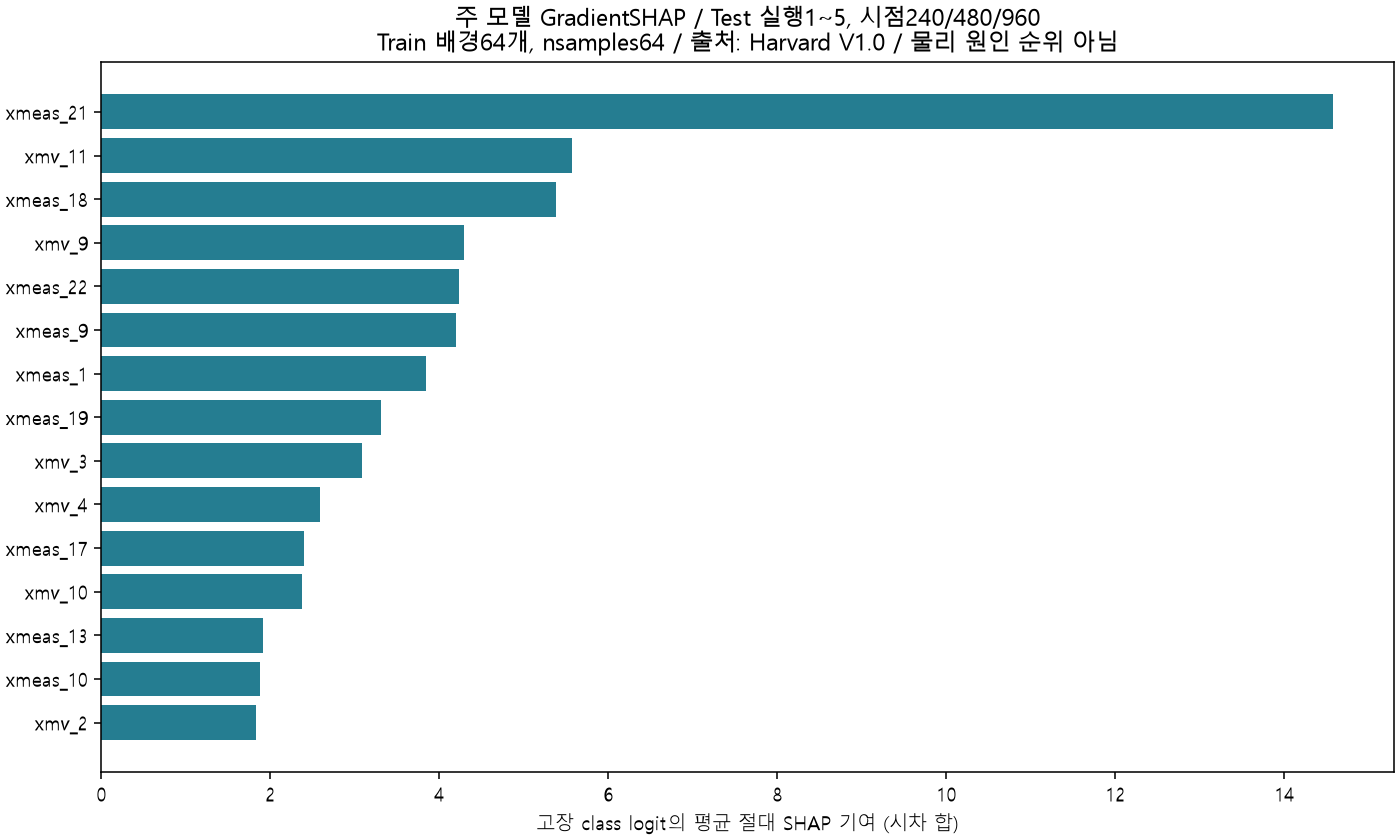

In [2]:
display(Image(filename=str(ROOT/'reports/figures/phase2/primary_shap.png')))
